# Volatility Models for Market Risk — walkthrough

This notebook is the interview demo. It runs the whole project top to bottom on **real** data
(Nifty 50, S&P 500, Reliance Industries, daily, 2015 → latest) and explains each step.

* **Part 1** – stylized facts: why constant volatility is wrong.
* **Part 2** – models: rolling windows, EWMA, GARCH(1,1) (by hand and with `arch`), GARCH‑t, GJR‑GARCH, Parkinson.
* **Part 3** – out-of-sample forecast evaluation: MSE, QLIKE, Mincer–Zarnowitz, ranking, COVID zoom.

Every computation lives in `src/`; the notebook calls the same functions as `main.py`, so the numbers here are the numbers in the docs.

In [1]:
# Make the project root importable (the notebook lives in notebooks/)
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

import main as pipeline
from src.config import Config

pd.set_option("display.precision", 4)
cfg = Config()
cfg.output_dir.mkdir(parents=True, exist_ok=True)
results = {}
OUT = cfg.output_dir

## Part 0 — Data

* Download daily OHLC + adjusted close with `yfinance` **once**, cache as CSV in `data/`, reuse afterwards.
* Clean: drop rows with missing / non-positive prices or `High == Low` (stale quote).
* Log returns $r_t = \ln(P_t/P_{t-1})$ on the adjusted close.
* Annualise with $\sigma_{annual} = \sigma_{daily}\sqrt{252}$.

If neither the download nor the cached CSVs are available, the next cell raises an error: synthetic data is never used for results.

In [2]:
data = pipeline.part0_data(cfg, results)
pd.read_csv(OUT / "data_cleaning.csv", index_col=0)

  NIFTY50: 2915 rows (2015-01-02 -> 2026-11-04), dropped 0, src=cache
  SP500: 2977 rows (2015-01-02 -> 2026-11-03), dropped 0, src=cache
  RELIANCE: 2922 rows (2015-01-01 -> 2026-11-04), dropped 2, src=cache


,rows_raw,dropped_missing,dropped_non_positive,dropped_high_eq_low,dropped_total,rows_clean,ticker,source,first_date,last_date
asset,,,,,,,,,,
NIFTY50,2915,0,0,0,0,2915,^NSEI,cache,2015-01-02,2026-11-04
SP500,2977,0,0,0,0,2977,^GSPC,cache,2015-01-02,2026-11-03
RELIANCE,2924,0,0,2,2,2922,RELIANCE.NS,cache,2015-01-01,2026-11-04


## Part 1 — Stylized facts

A constant-volatility normal model implies: skewness 0, excess kurtosis 0, no autocorrelation in squared returns, and no link between today's sign and tomorrow's size. We test all four.

In [3]:
pipeline.part1_stylized_facts(data, cfg, results)
facts = pd.read_csv(OUT / "stylized_facts.csv", index_col=0)
facts[["n_obs", "vol_annual", "skewness", "excess_kurtosis", "jb_stat", "jb_pvalue",
       "obs_4sigma_days", "exp_4sigma_days_normal"]]

          vol_annual  skewness  excess_kurtosis  jb_pvalue  corr_r_next_r2
NIFTY50       0.1625   -1.2866          19.5837        0.0          0.0483
SP500         0.1765   -0.6436          15.9321        0.0         -0.0783
RELIANCE      0.2698    0.1667           8.5032        0.0          0.0254


,n_obs,vol_annual,skewness,excess_kurtosis,jb_stat,jb_pvalue,obs_4sigma_days,exp_4sigma_days_normal
NIFTY50,2914.0,0.1625,-1.2866,19.5837,47199.7493,0.0,16.0,0.1846
SP500,2976.0,0.1765,-0.6436,15.9321,31567.0085,0.0,22.0,0.1885
RELIANCE,2921.0,0.2698,0.1667,8.5032,8779.2149,0.0,18.0,0.1850


**Fat tails.** Excess kurtosis far above 0 and Jarque–Bera p-values ≈ 0 reject normality. The 4‑sigma count compares observed extreme days with what a normal distribution predicts.

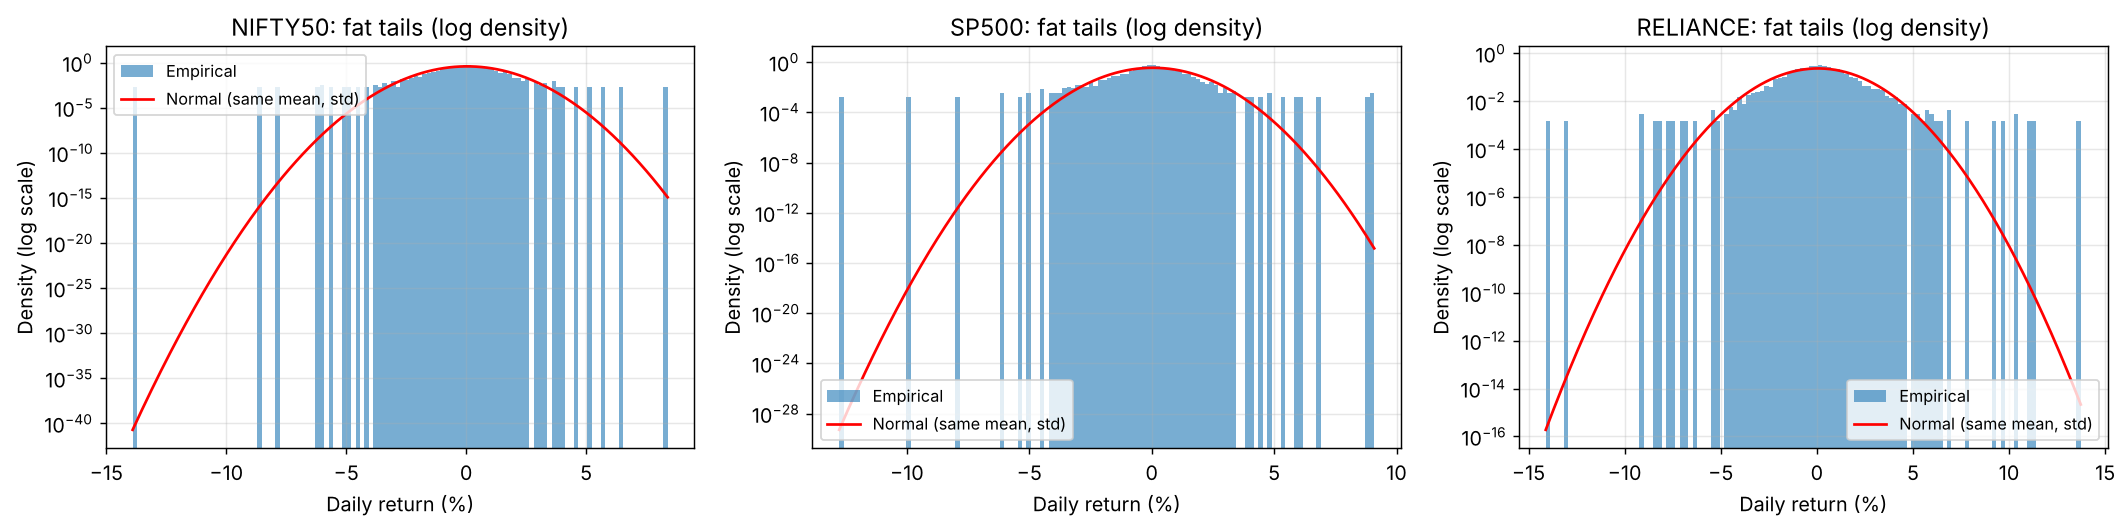

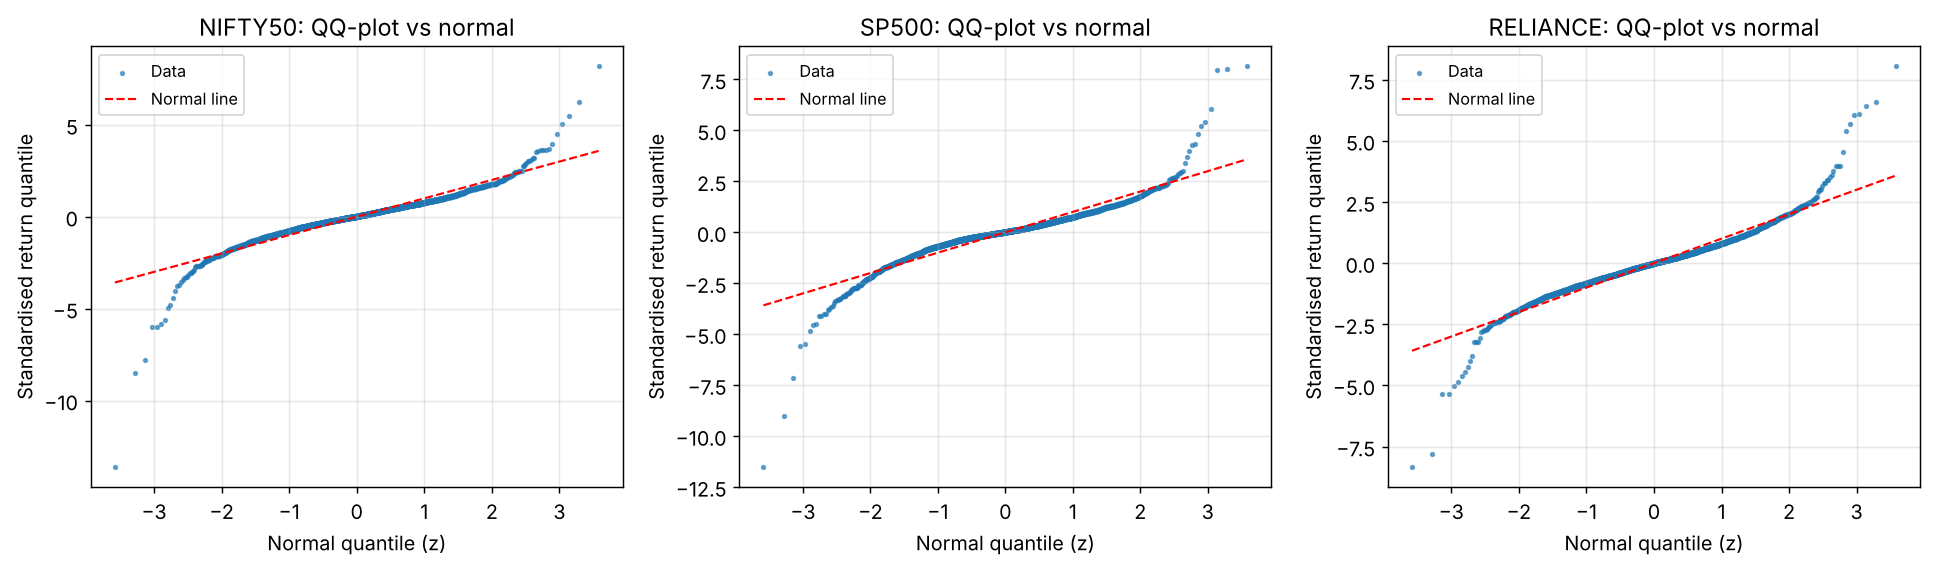

In [4]:
display(Image(OUT / "02_hist_vs_normal.png"))
display(Image(OUT / "03_qq_plot.png"))

**Volatility clustering.** Big moves come in bursts: |r| shows calm and turbulent regimes. Returns themselves are nearly uncorrelated, but squared returns are strongly autocorrelated — Ljung–Box rejects "no autocorrelation" for $r_t^2$ much more strongly than for $r_t$.

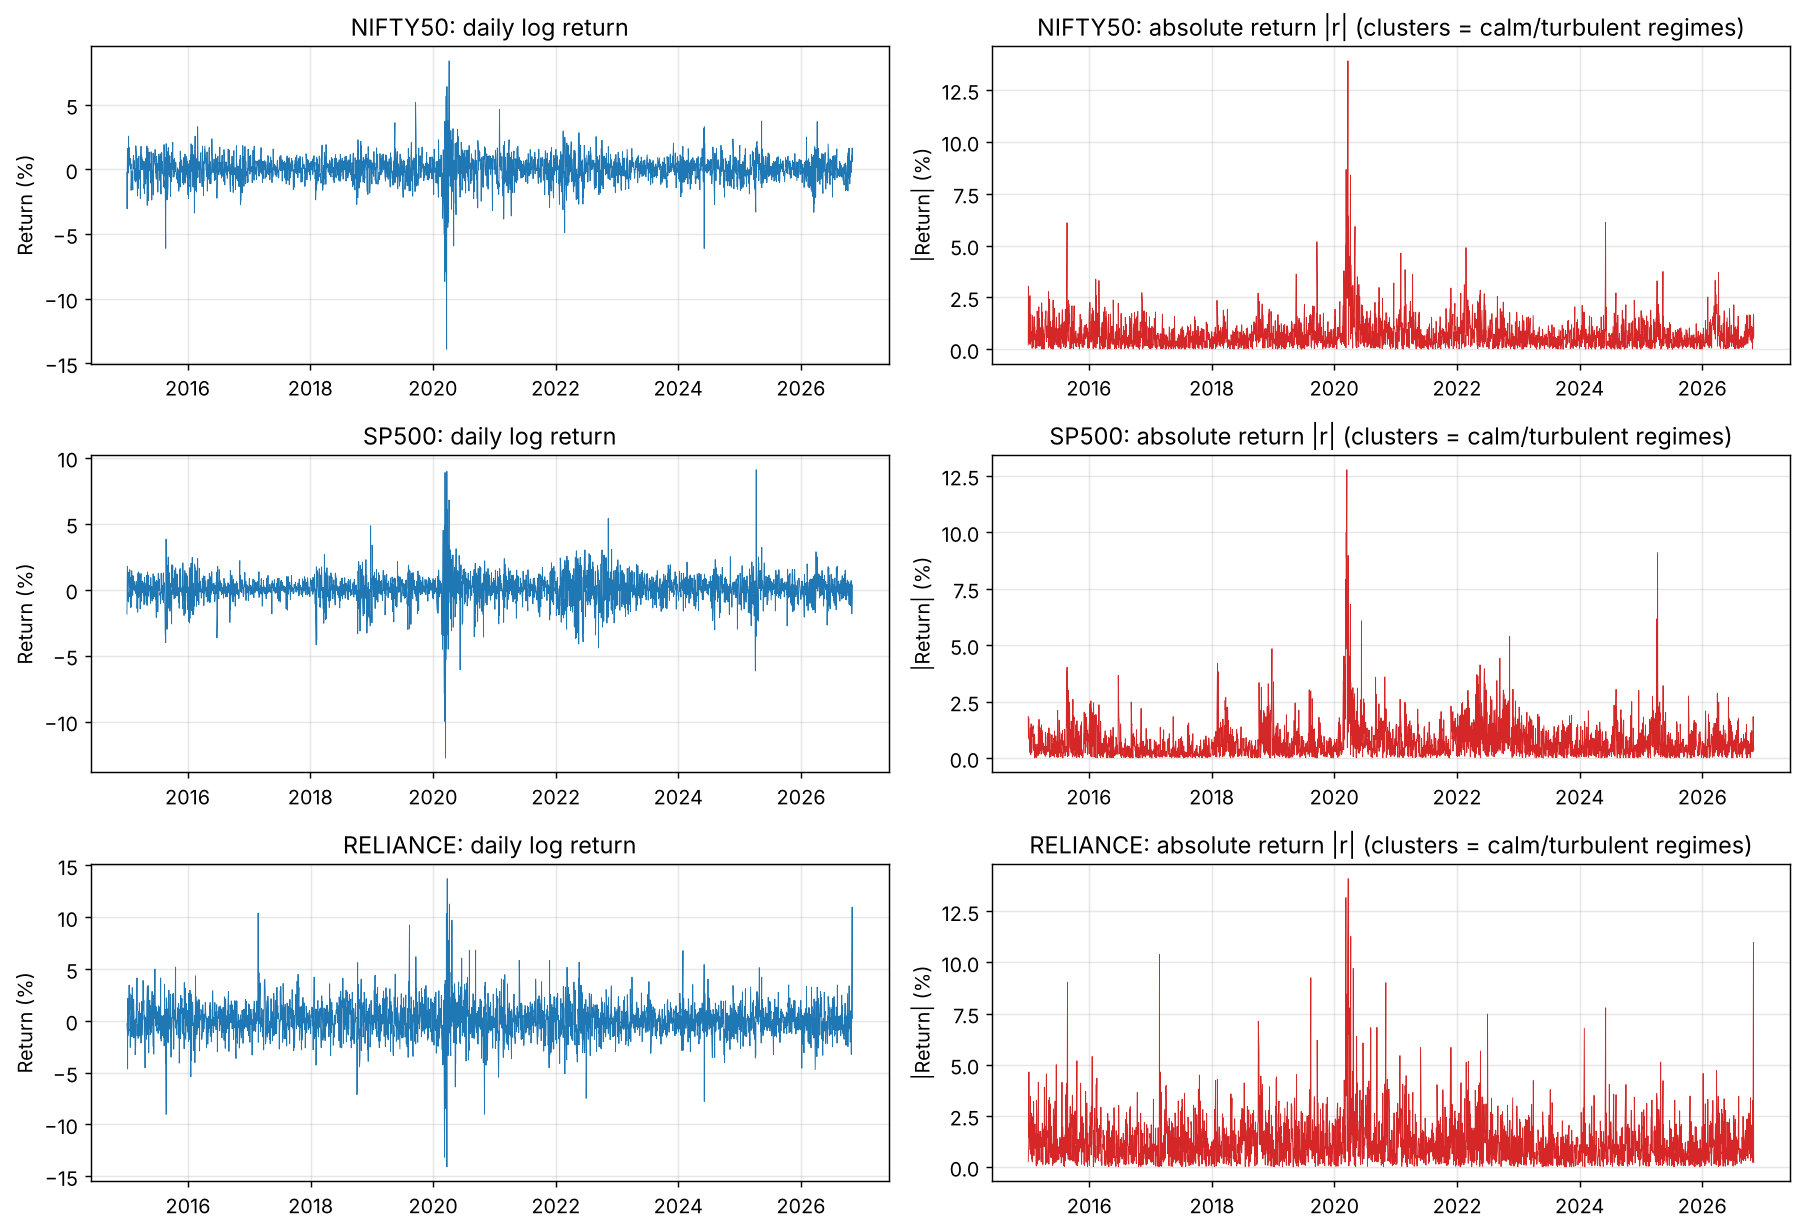

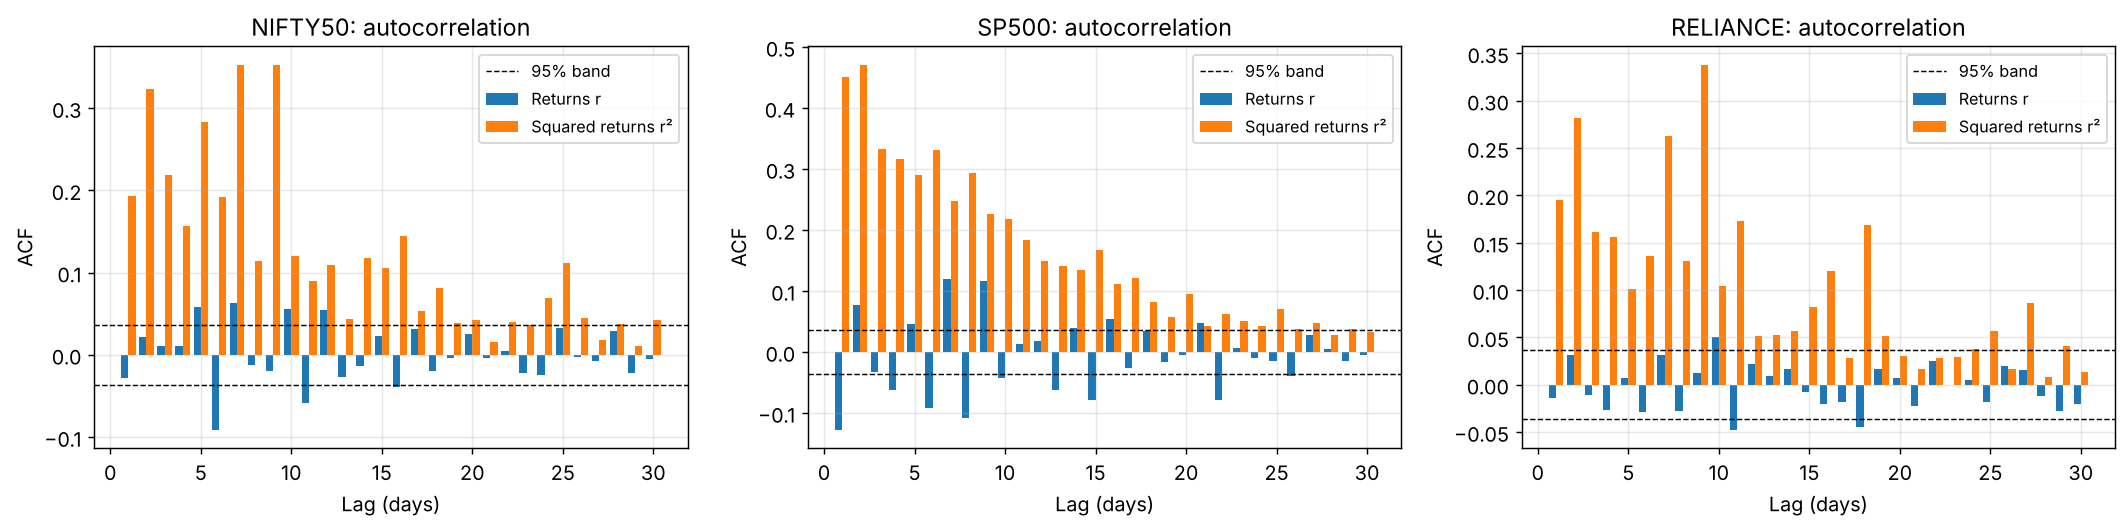

,lag,Q_stat,p_value,asset,series
0,10,60.6293,2.7546e-09,NIFTY50,returns
1,20,94.1906,1.3595e-11,NIFTY50,returns
2,10,1773.0197,0.0000e+00,NIFTY50,squared_returns
3,20,2008.7267,0.0000e+00,NIFTY50,squared_returns
4,10,235.5489,5.8894e-45,SP500,returns
5,20,287.8546,2.4239e-49,SP500,returns
6,10,3203.3007,0.0000e+00,SP500,squared_returns
7,20,3705.8774,0.0000e+00,SP500,squared_returns
8,10,21.6810,1.6815e-02,RELIANCE,returns
9,20,39.8881,5.1607e-03,RELIANCE,returns


In [5]:
display(Image(OUT / "01_returns_clustering.png"))
display(Image(OUT / "04_acf_returns_vs_squared.png"))
pd.read_csv(OUT / "ljung_box.csv")

**Leverage effect.** A negative $\text{corr}(r_t, r_{t+1}^2)$ means falls are followed by larger moves than rises.

In [6]:
facts[["corr_r_next_r2", "corr_r_next_absr"]]

,corr_r_next_r2,corr_r_next_absr
NIFTY50,0.0483,-0.0502
SP500,-0.0783,-0.1195
RELIANCE,0.0254,-0.0098


**Conclusion.** Volatility is not constant: it clusters and is predictable from recent squared returns, tails are fat, and down-moves raise future volatility more than up-moves. A model with a single σ for the whole sample under-states risk in turbulent periods and over-states it in calm ones. We need models where σ²ₜ depends on recent returns: EWMA and the GARCH family (with fat-tailed and asymmetric variants).

## Part 2.1 — Historical (rolling) volatility

$\sigma_t(N) = \sqrt{\tfrac{1}{N-1}\sum_{i=0}^{N-1}(r_{t-i}-\bar r)^2}$ — equal weight on the last N days.
Short windows are responsive but noisy; long windows are smooth but slow. The **ghost effect**: a single extreme day keeps the estimate high for exactly N days, then it drops abruptly when the day leaves the window.

In [7]:
pipeline.part2_historical(data, cfg, results)
pd.DataFrame({a: v["avg_abs_daily_change"] for a, v in results["historical"].items()}).T

,20-day,60-day,252-day
NIFTY50,0.0054,0.0020,0.0005
SP500,0.0058,0.0022,0.0006
RELIANCE,0.0097,0.0032,0.0008


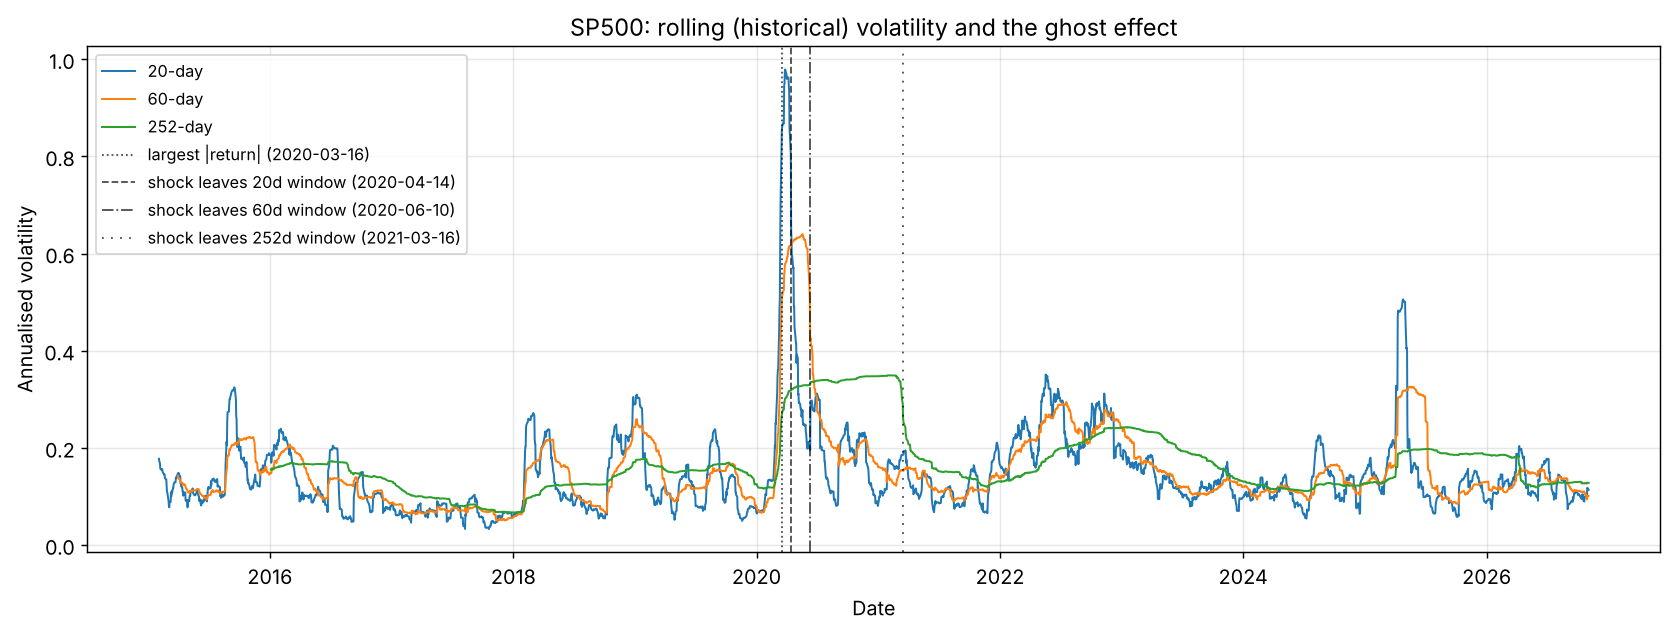

In [8]:
display(Image(OUT / "05_hist_vol_SP500.png"))

## Part 2.2 — EWMA (RiskMetrics)

$\sigma^2_t = \lambda\sigma^2_{t-1} + (1-\lambda) r^2_{t-1}$, λ = 0.94. Initialisation: $\sigma^2_1 = r_0^2$ (no future data; its weight decays like $\lambda^t$).
Below: the explicit loop and pandas `.ewm(adjust=False)` give the same numbers.

In [9]:
from src.models.ewma import ewma_variance_loop, ewma_variance_pandas
r_sp = data["SP500"]["ret"]
loop = ewma_variance_loop(r_sp, 0.94)
fast = ewma_variance_pandas(r_sp, 0.94)
print("max |loop - pandas| =", float(np.nanmax(np.abs(loop - fast))))
assert np.allclose(loop, fast, equal_nan=True)

max |loop - pandas| = 4.336808689942018e-19


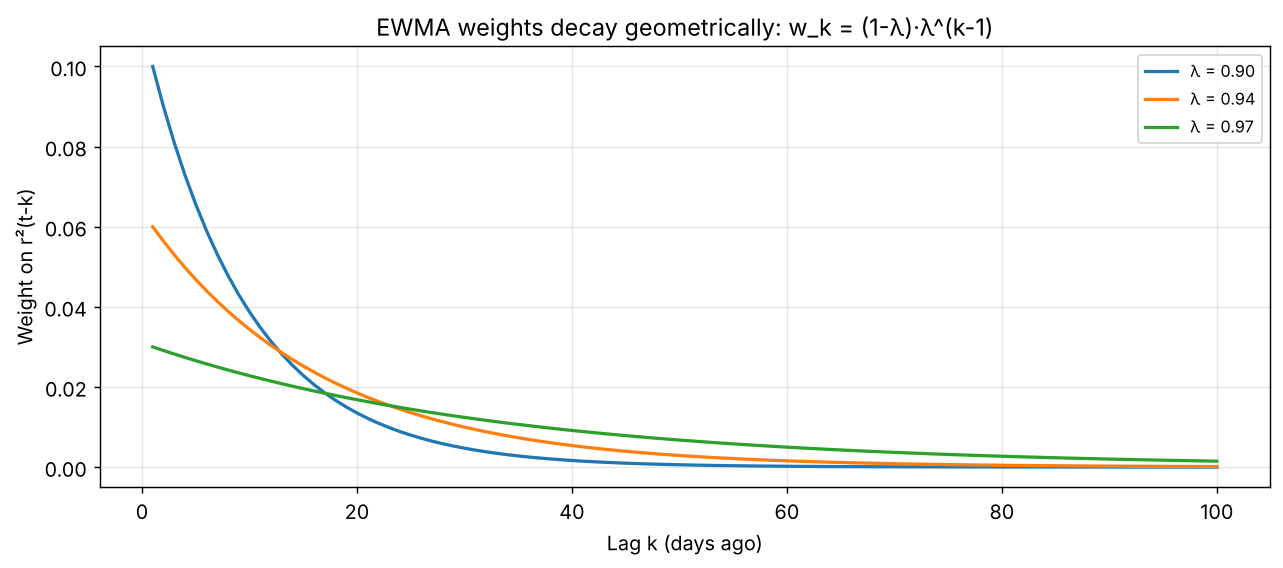

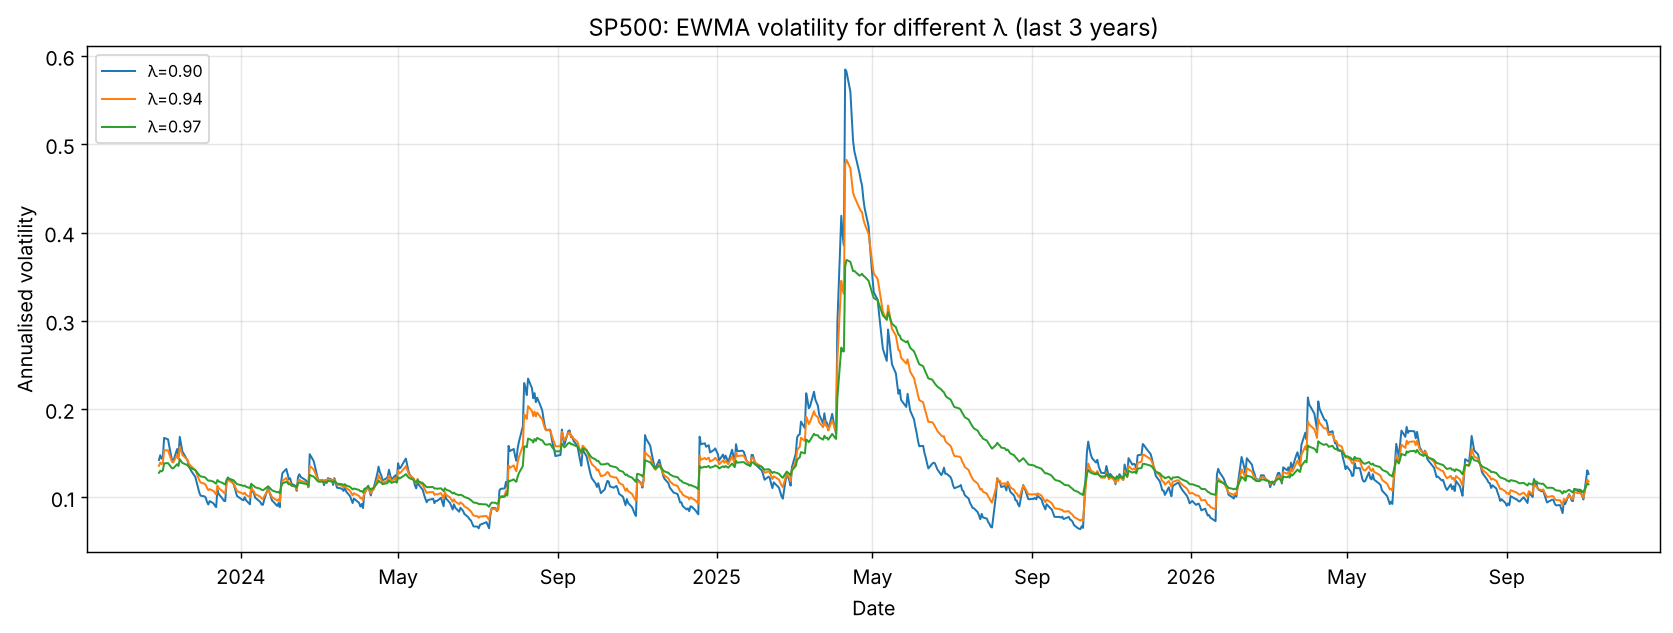

{'0.9': np.float64(6.578813478960585),
 '0.94': np.float64(11.202305583621158),
 '0.97': np.float64(22.75657306277341)}

In [10]:
pipeline.part2_ewma(data, cfg, results)
display(Image(OUT / "06_ewma_weights.png"))
display(Image(OUT / "07_ewma_lambdas_SP500.png"))
results["ewma"]["half_life_days"]

## Part 2.3 — GARCH(1,1) by hand

$\sigma^2_t = \omega + \alpha r^2_{t-1} + \beta\sigma^2_{t-1}$, with normal log-likelihood
$\ln L = -\tfrac12\sum_t [\ln 2\pi + \ln\sigma_t^2 + r_t^2/\sigma_t^2]$ maximised by `scipy.optimize.minimize` (SLSQP) subject to ω > 0, α, β ≥ 0, α + β < 1.
Returns are multiplied by 100 so that ω is ~0.01–0.1 instead of ~1e‑6 (better-conditioned optimisation). Using the same backcast (sample variance) as the manual version, `arch` gives the same estimates.

In [11]:
pipeline.part2_garch_manual(data, cfg, results)
pd.read_csv(OUT / "garch_manual_vs_arch.csv", index_col=0)

,manual,arch,abs_diff,asset
omega,0.0236,0.0236,1.2741e-06,NIFTY50
alpha,0.0992,0.0992,4.5880e-07,NIFTY50
beta,0.8770,0.8770,2.1368e-06,NIFTY50
loglik,-3735.6000,-3735.6000,2.7481e-08,NIFTY50
omega,0.0394,0.0394,5.2158e-07,SP500
alpha,0.1551,0.1551,3.5202e-06,SP500
beta,0.8088,0.8088,1.5841e-06,SP500
loglik,-3846.4459,-3846.4459,5.0274e-08,SP500
omega,0.1450,0.1450,1.1934e-06,RELIANCE
alpha,0.0777,0.0777,7.6045e-07,RELIANCE


## Part 2.4 — GARCH with `arch`: normal vs Student‑t, GJR, term structure

Key numbers: persistence α+β, long-run variance $V_L=\omega/(1-\alpha-\beta)$, long-run annual vol, half-life $\ln 0.5/\ln(\alpha+\beta)$.
EWMA is the special case ω = 0, α = 1−λ, β = λ (α+β = 1: no mean reversion, no long-run level) — asserted in `part2_ewma`.

In [12]:
pipeline.part2_garch_arch(data, cfg, results)
summary = pd.read_csv(OUT / "garch_summary.csv", index_col=0)
summary[["normal_persistence", "normal_long_run_annual_vol", "normal_half_life_days",
         "t_persistence", "t_nu", "next_day_vol_annual"]]

          normal_persistence  normal_long_run_annual_vol  normal_half_life_days    t_nu  gjr_gamma_p
NIFTY50               0.9760                      0.1581                28.5733  7.0023       0.0000
SP500                 0.9639                      0.1660                18.8776  5.7607       0.0000
RELIANCE              0.9484                      0.2660                13.0800  5.2315       0.0155


,normal_persistence,normal_long_run_annual_vol,normal_half_life_days,t_persistence,t_nu,next_day_vol_annual
NIFTY50,0.9760,0.1581,28.5733,0.9693,7.0023,0.1581
SP500,0.9639,0.1660,18.8776,0.9905,5.7607,0.1374
RELIANCE,0.9484,0.2660,13.0800,0.9723,5.2315,0.4800


In [13]:
params = pd.read_csv(OUT / "garch_params.csv", index_col=0)
params[params["asset"] == "SP500"]

,estimate,std_err,t_stat,p_value,asset,model
omega,0.0394,0.0102,3.8651,1.1106e-04,SP500,GARCH-normal
alpha[1],0.1551,0.0228,6.7943,1.0882e-11,SP500,GARCH-normal
beta[1],0.8089,0.0259,31.2210,5.5348e-214,SP500,GARCH-normal
omega,0.0218,0.0061,3.5720,3.5429e-04,SP500,GARCH-t
alpha[1],0.1530,0.0195,7.8555,3.9809e-15,SP500,GARCH-t
beta[1],0.8375,0.0191,43.7795,0.0000e+00,SP500,GARCH-t
nu,5.7607,0.6202,9.2886,1.5629e-20,SP500,GARCH-t
omega,0.0402,0.0098,4.1010,4.1143e-05,SP500,GJR-GARCH
alpha[1],0.0328,0.0279,1.1750,2.3999e-01,SP500,GJR-GARCH
gamma[1],0.2236,0.0449,4.9775,6.4396e-07,SP500,GJR-GARCH


**Normal vs Student-t errors.** Higher log-likelihood and lower AIC/BIC favour the t; a small ν (degrees of freedom) means fat tails remain even after GARCH removes the clustering.

In [14]:
pd.read_csv(OUT / "garch_information_criteria.csv", index_col=0)

,loglik,n_params,aic,bic,asset
GARCH-normal,-3734.8912,3.0,7475.7824,7493.7142,NIFTY50
GARCH-t,-3668.3091,4.0,7344.6183,7368.5274,NIFTY50
GJR-GARCH,-3693.9222,4.0,7395.8444,7419.7535,NIFTY50
GARCH-normal,-3846.5696,3.0,7699.1391,7717.1341,SP500
GARCH-t,-3754.7977,4.0,7517.5954,7541.5887,SP500
GJR-GARCH,-3791.1469,4.0,7590.2938,7614.2872,SP500
GARCH-normal,-5484.6365,3.0,10975.2729,10993.2120,RELIANCE
GARCH-t,-5347.2685,4.0,10702.5370,10726.4557,RELIANCE
GJR-GARCH,-5471.8256,4.0,10951.6511,10975.5698,RELIANCE


**Term structure.** $E[\sigma^2_{t+h}] = V_L + (\alpha+\beta)^{h-1}(\sigma^2_{t+1}-V_L)$: forecasts mean-revert to the long-run level (manual formula asserted equal to `arch`).

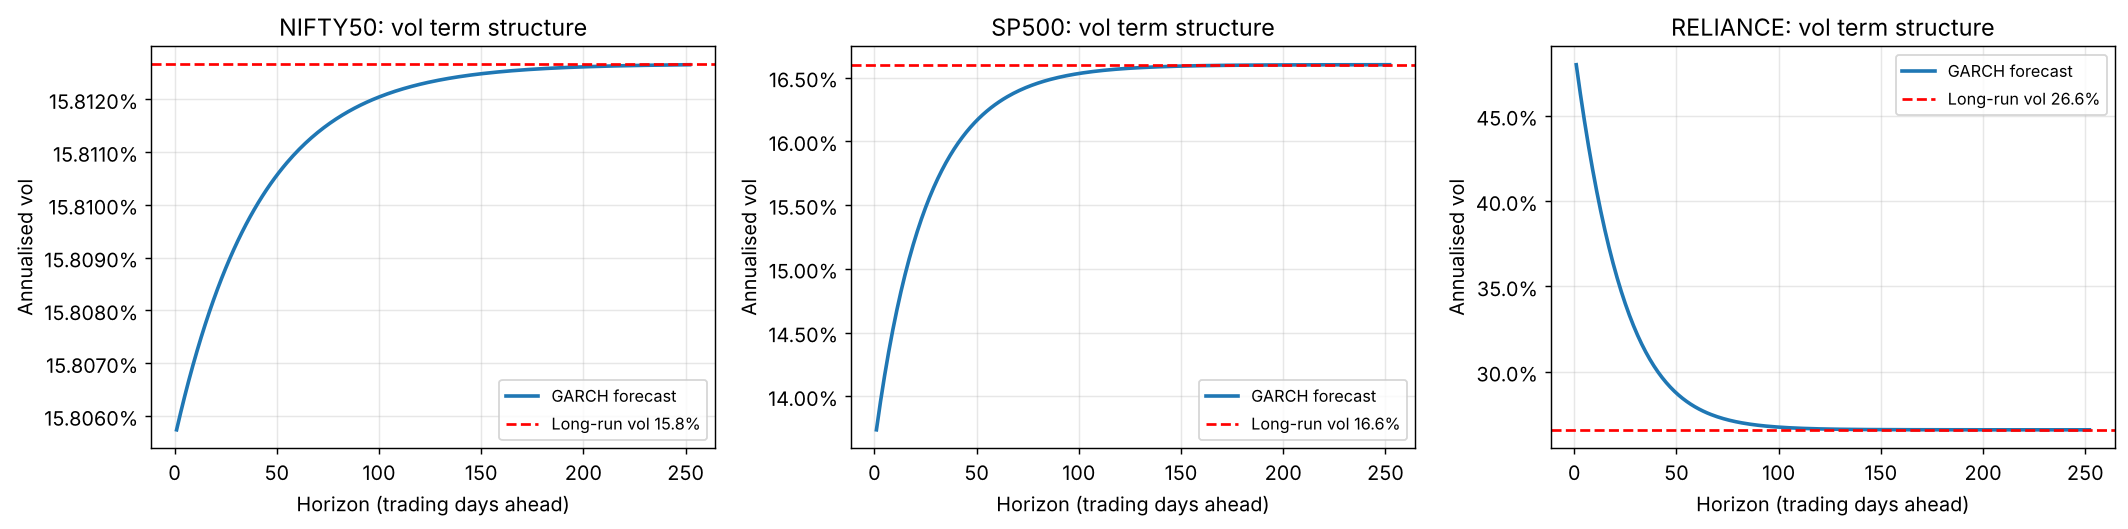

In [15]:
display(Image(OUT / "08_garch_term_structure.png"))

**GJR-GARCH and the leverage effect.** $\sigma^2_t = \omega + (\alpha + \gamma I_{t-1}) r^2_{t-1} + \beta\sigma^2_{t-1}$, $I_{t-1}=1$ if $r_{t-1}<0$. γ > 0 and significant (t-stat, p-value) ⇒ bad news raises variance more than good news. The news impact curve becomes steeper on the left.

In [16]:
summary[["gjr_alpha", "gjr_gamma", "gjr_gamma_t", "gjr_gamma_p", "gjr_beta", "gjr_persistence"]]

,gjr_alpha,gjr_gamma,gjr_gamma_t,gjr_gamma_p,gjr_beta,gjr_persistence
NIFTY50,0.0233,0.1526,4.2449,2.1870e-05,0.8647,0.9642
SP500,0.0328,0.2236,4.9775,6.4396e-07,0.8224,0.9670
RELIANCE,0.0326,0.0761,2.4210,1.5476e-02,0.8833,0.9539


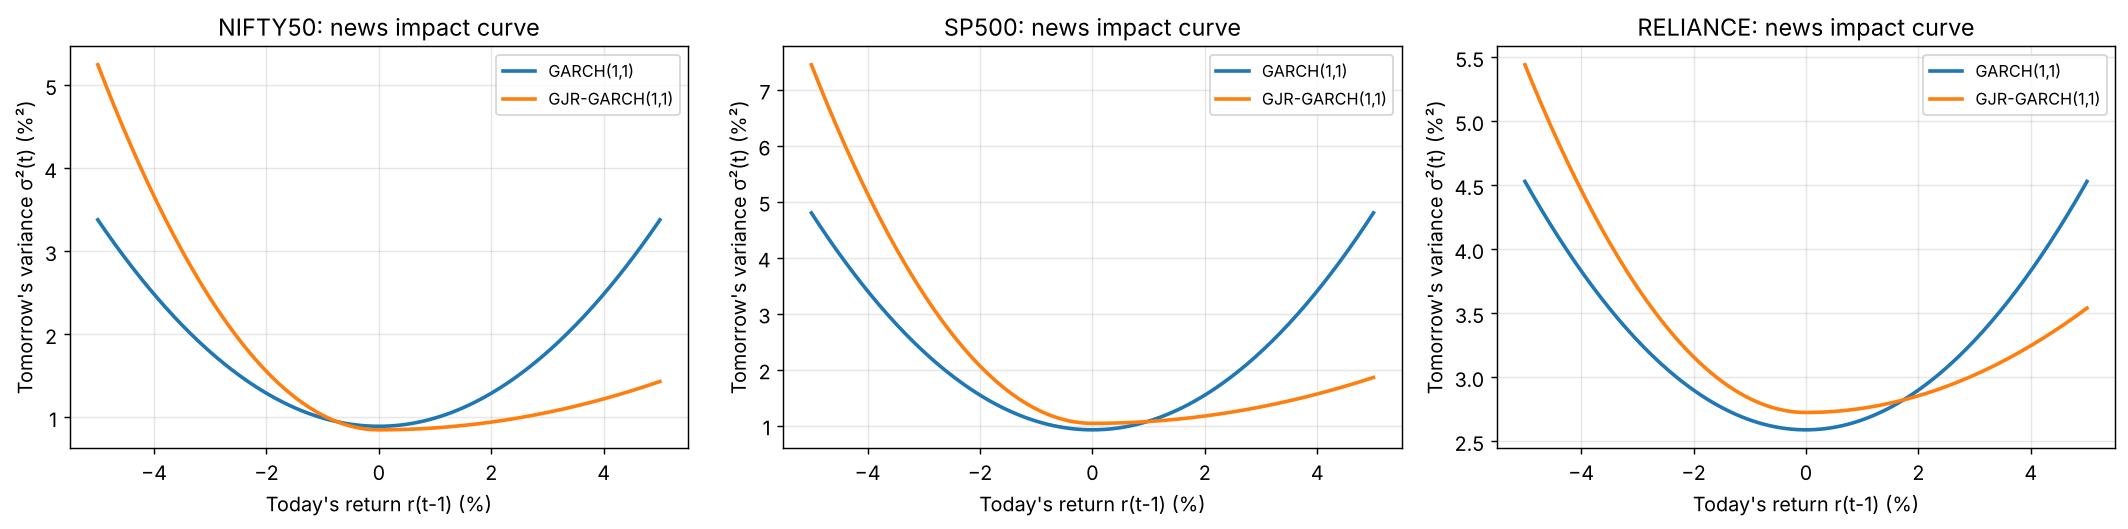

In [17]:
display(Image(OUT / "09_news_impact_curve.png"))

## Part 2.5 — Parkinson range-based volatility

$\sigma^2_P = \frac{1}{4\ln 2}(\ln H/L)^2$ uses the intraday range (≈5× more efficient than close-to-close for a driftless random walk) but misses overnight gaps, so it is biased down where gaps are large.

In [18]:
pipeline.part2_parkinson(data, cfg, results)
pd.DataFrame(results["parkinson"]).T

,mean_ratio_park_to_cc,mean_park_vol,mean_cc_vol,overnight_variance_share
NIFTY50,0.8433,0.1141,0.1405,0.3990
SP500,0.8061,0.1147,0.1478,0.2121
RELIANCE,0.9217,0.2192,0.2455,0.2257


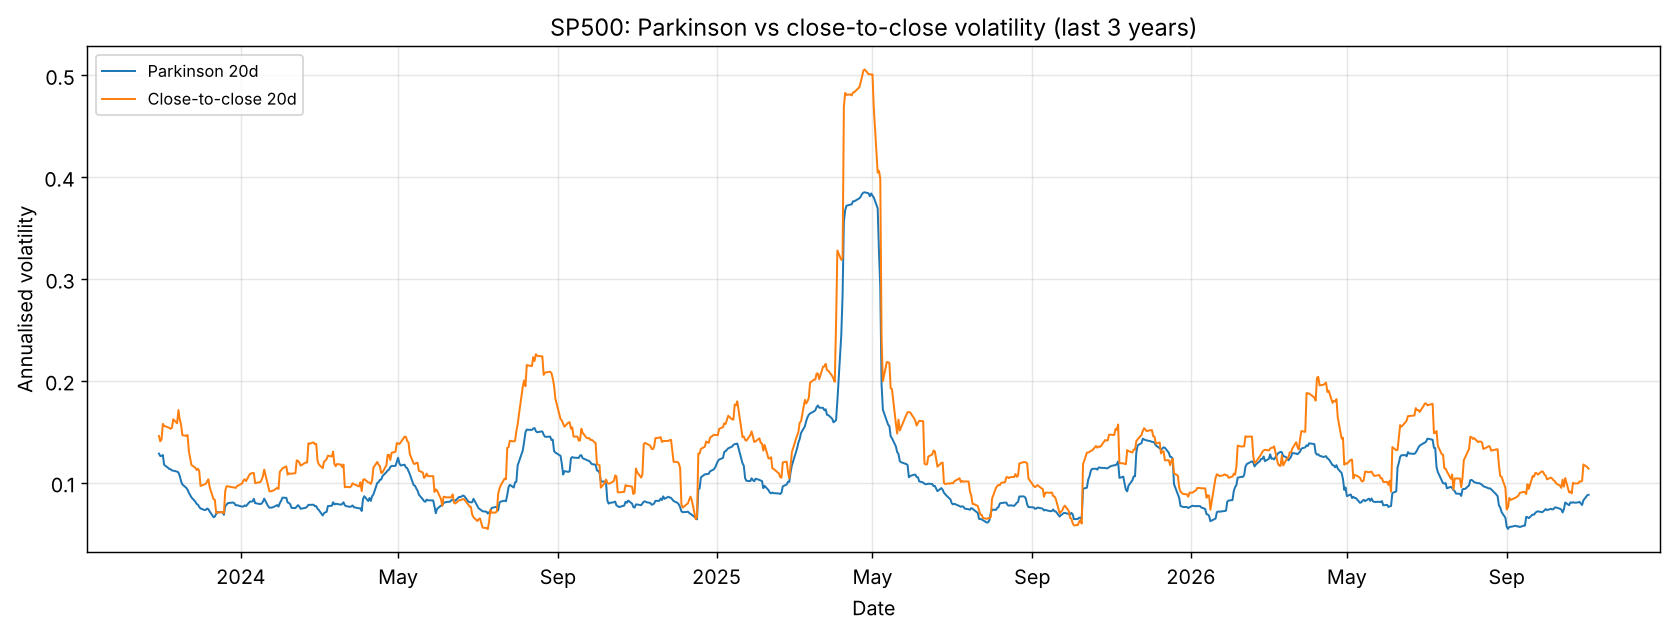

In [19]:
display(Image(OUT / "10_parkinson_SP500.png"))

## Part 3 — Out-of-sample forecast evaluation

* Expanding window: first 1000 returns for estimation only; GARCH-type models refit every 20 days on data **before** the forecast date — no look-ahead (see `tests/test_no_lookahead.py`).
* Proxy: $RV_t = r_t^2$. Losses: MSE $=\overline{(RV-h)^2}$, QLIKE $=\overline{RV/h + \ln h}$ (robust ranking with a noisy proxy, not dominated by a few crash days).
* Mincer–Zarnowitz: $RV_t = a + b h_t + e_t$; unbiased forecasts have a = 0, b = 1.

This cell takes a few minutes (≈900 GARCH fits).

In [20]:
pipeline.part3_evaluation(data, cfg, results)

  NIFTY50: 1914 OOS days from 2019-01-30, best QLIKE=GJR-GARCH, best MSE=GJR-GARCH (5s)


  SP500: 1976 OOS days from 2018-12-24, best QLIKE=GJR-GARCH, best MSE=GARCH (6s)


  RELIANCE: 1921 OOS days from 2019-01-22, best QLIKE=GJR-GARCH, best MSE=GJR-GARCH (8s)


asset      NIFTY50  RELIANCE  SP500  mean_rank
model                                         
GJR-GARCH        1         1      1     1.0000
GARCH            2         3      2     2.3333
GARCH-t          3         2      3     2.6667
EWMA             4         4      4     4.0000
HIST20           5         5      5     5.0000
HIST60           6         6      6     6.0000
PARK20           7         7      7     7.0000
HIST252          8         8      8     8.0000


In [21]:
ranking = pd.read_csv(OUT / "model_ranking.csv", index_col=0)
ranking

,asset,MSE,QLIKE,rank_QLIKE,rank_MSE
model,,,,,
GJR-GARCH,NIFTY50,29.1107,0.7805,1,1
GARCH,NIFTY50,30.0492,0.8009,2,3
GARCH-t,NIFTY50,30.0755,0.8063,3,4
EWMA,NIFTY50,30.3223,0.8244,4,5
HIST20,NIFTY50,32.3844,0.8577,5,6
HIST60,NIFTY50,33.8757,0.9428,6,7
PARK20,NIFTY50,29.7905,1.0061,7,2
HIST252,NIFTY50,34.1441,1.0825,8,8
GJR-GARCH,SP500,28.7296,0.9155,1,3


In [22]:
pd.read_csv(OUT / "rank_summary_qlike.csv", index_col=0)

,NIFTY50,RELIANCE,SP500,mean_rank
model,,,,
GJR-GARCH,1,1,1,1.0000
GARCH,2,3,2,2.3333
GARCH-t,3,2,3,2.6667
EWMA,4,4,4,4.0000
HIST20,5,5,5,5.0000
HIST60,6,6,6,6.0000
PARK20,7,7,7,7.0000
HIST252,8,8,8,8.0000


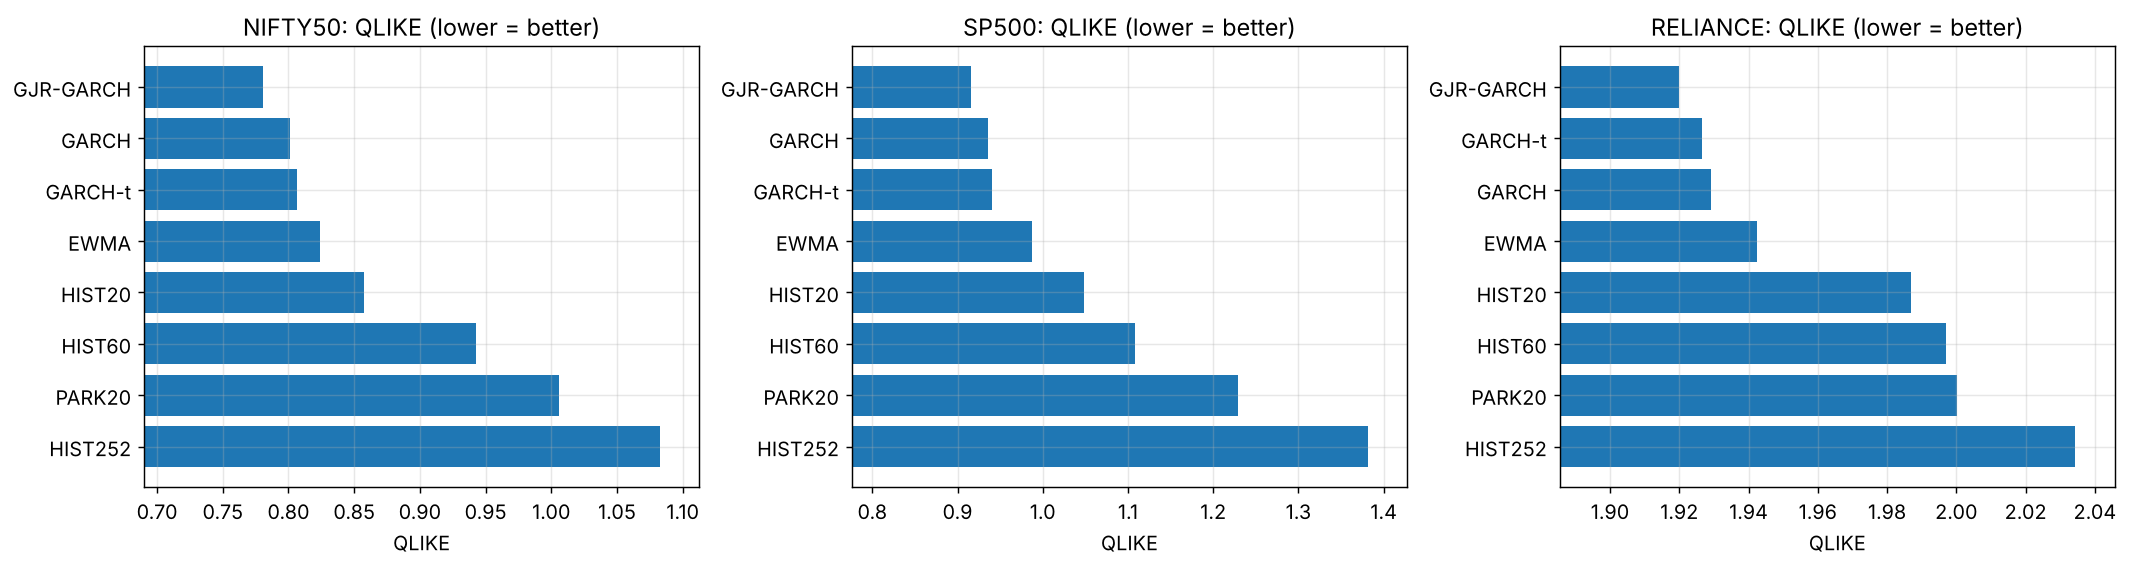

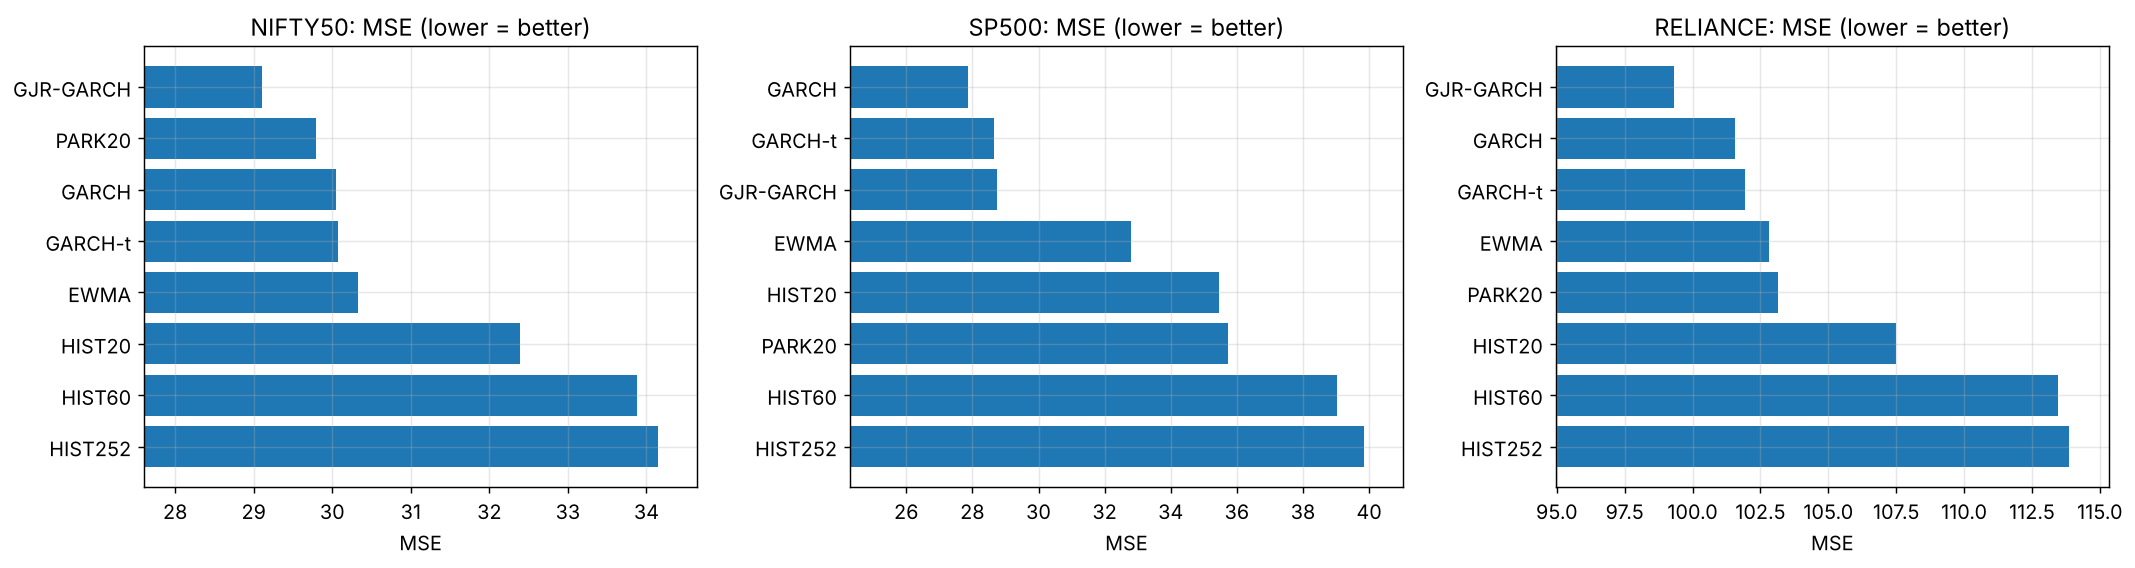

In [23]:
display(Image(OUT / "13_qlike_by_model.png"))
display(Image(OUT / "14_mse_by_model.png"))

In [24]:
mz = pd.read_csv(OUT / "mincer_zarnowitz.csv", index_col=0)
mz

,asset,a,b,se_a,se_b,r2,p_joint_a0_b1
model,,,,,,,
HIST20,NIFTY50,0.4822,0.6075,0.1722,0.2291,0.0879,1.1686e-02
HIST60,NIFTY50,0.5729,0.5309,0.1459,0.1991,0.0343,4.5535e-04
HIST252,NIFTY50,0.6155,0.4947,0.1541,0.1624,0.0082,9.1009e-05
EWMA,NIFTY50,0.1989,0.8382,0.1999,0.2633,0.1159,4.3844e-01
PARK20,NIFTY50,0.1643,1.4427,0.3000,0.5707,0.1481,1.0920e-05
GARCH,NIFTY50,0.1961,0.8718,0.1992,0.2575,0.1223,3.7602e-01
GARCH-t,NIFTY50,0.0867,1.0270,0.2261,0.3040,0.1193,4.1760e-01
GJR-GARCH,NIFTY50,0.2918,0.7532,0.1600,0.1814,0.1648,1.7226e-01
HIST20,SP500,0.5130,0.6491,0.1963,0.2217,0.1398,1.7767e-02


### COVID-19 crash zoom

How fast does each model react to the February–March 2020 sell-off, and how fast does it decay afterwards?

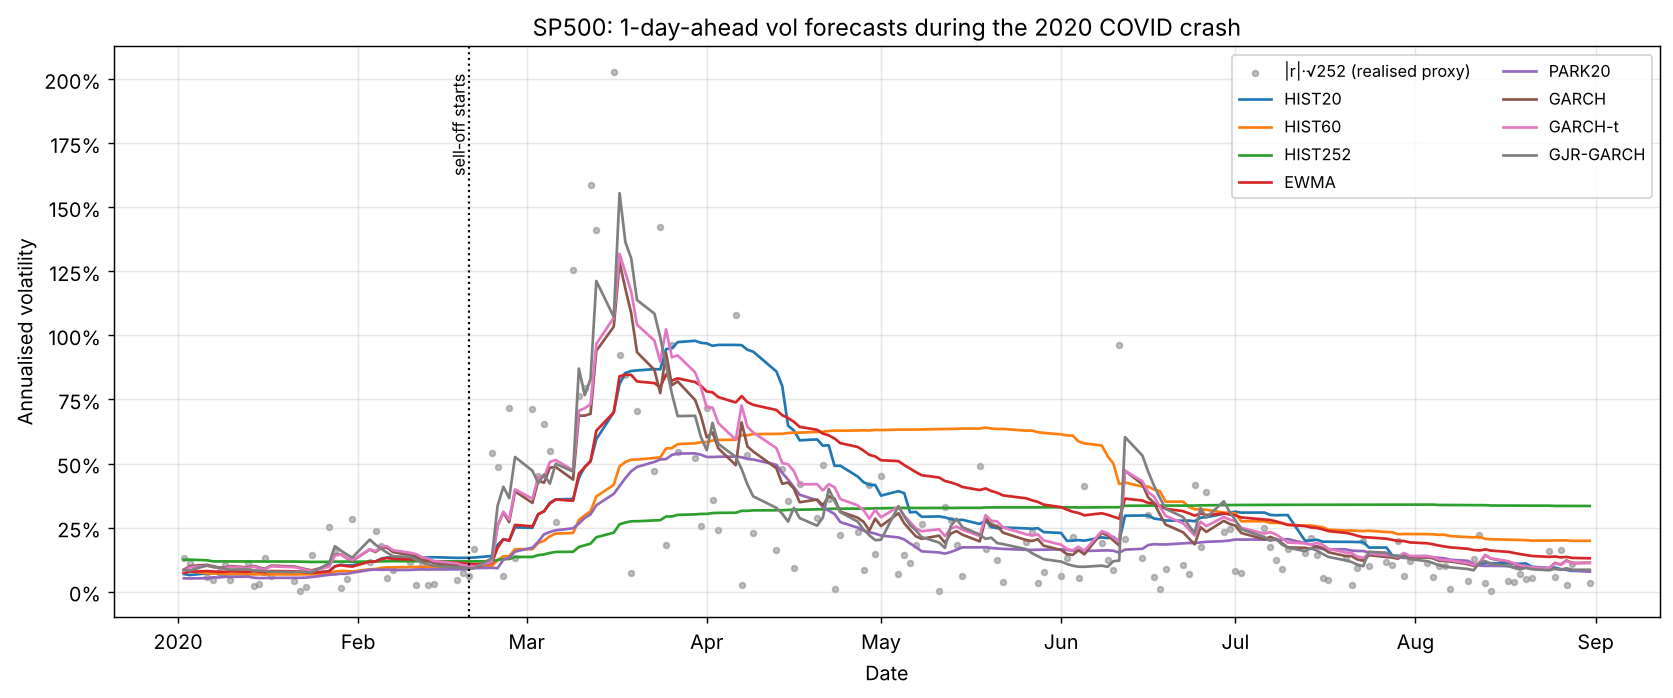

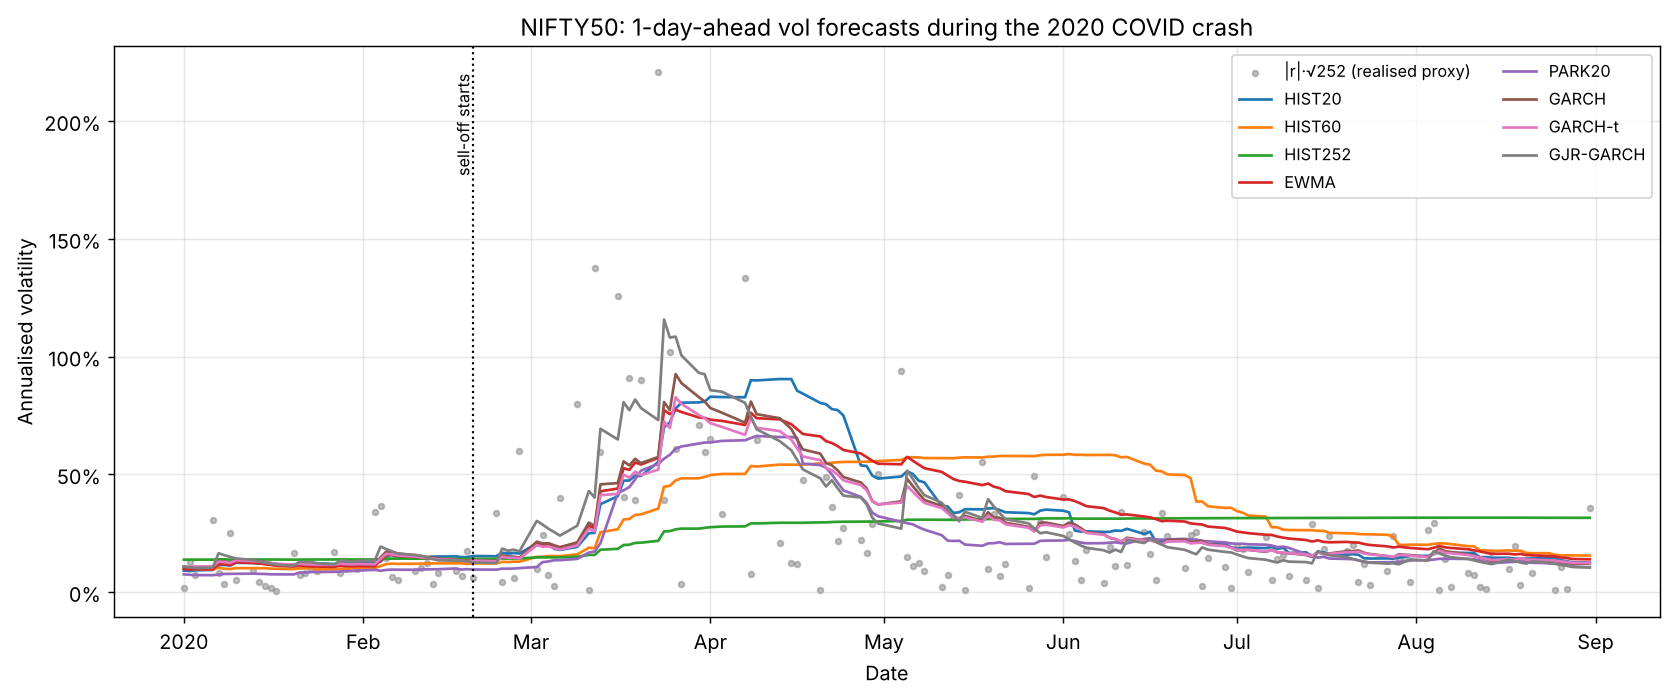

,asset,pre_shock_vol,peak_vol,peak_date,days_to_peak,days_peak_to_half_decay
model,,,,,,
HIST20,NIFTY50,0.1487,0.9049,2020-04-13,32,11.0
HIST60,NIFTY50,0.1196,0.5863,2020-06-02,65,21.0
HIST252,NIFTY50,0.1412,0.3165,2020-08-07,113,NaN
EWMA,NIFTY50,0.1309,0.7739,2020-03-26,23,34.0
PARK20,NIFTY50,0.0974,0.6630,2020-04-09,31,11.0
GARCH,NIFTY50,0.1318,0.9257,2020-03-26,23,16.0
GARCH-t,NIFTY50,0.1307,0.8278,2020-03-26,23,17.0
GJR-GARCH,NIFTY50,0.1310,1.1576,2020-03-24,21,11.0
HIST20,SP500,0.1321,0.9790,2020-03-30,27,17.0


In [25]:
display(Image(OUT / "12_covid_zoom_SP500.png"))
display(Image(OUT / "12_covid_zoom_NIFTY50.png"))
pd.read_csv(OUT / "covid_reaction.csv", index_col=0)

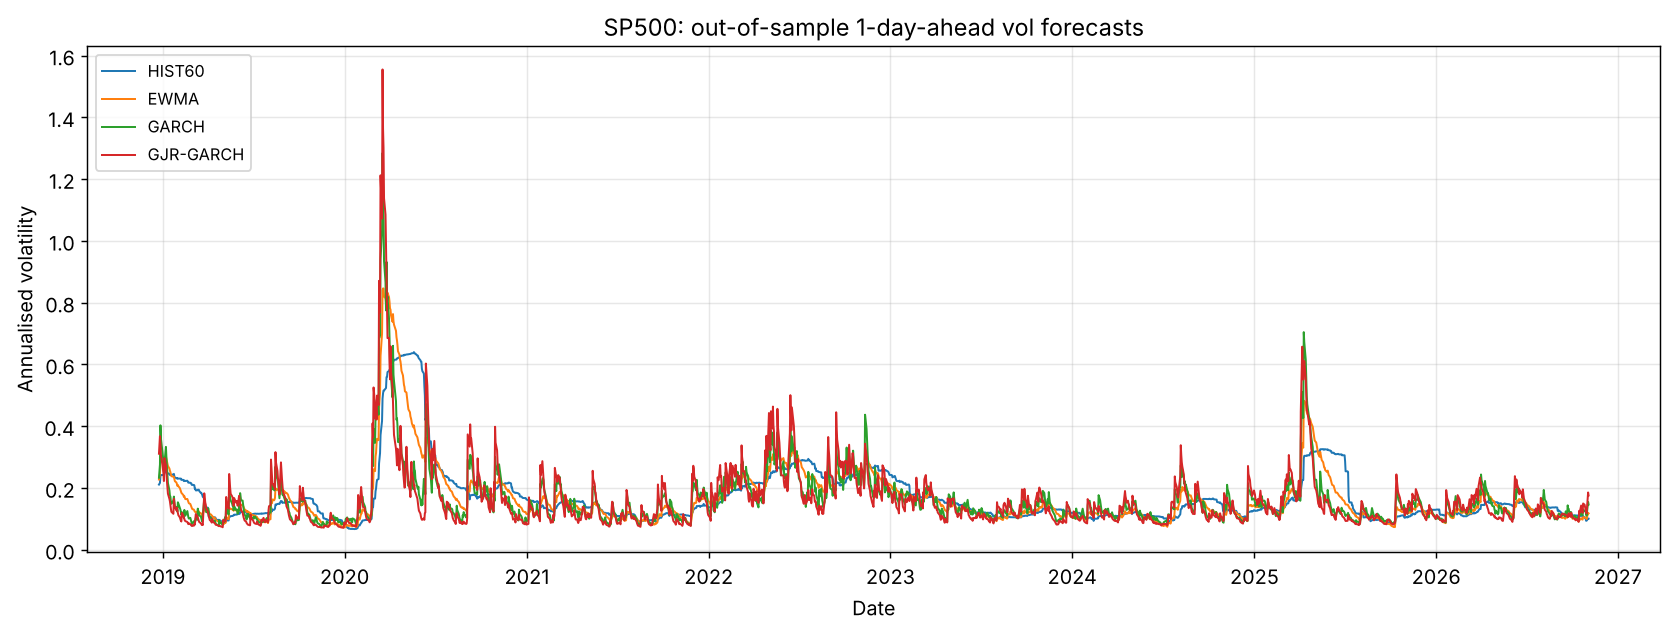

(46488, 5)


,date,asset,model,sigma_daily,sigma_annual
0,2019-01-30,NIFTY50,HIST20,0.0062,0.0988
1,2019-01-30,NIFTY50,HIST60,0.0078,0.1243
2,2019-01-30,NIFTY50,HIST252,0.0081,0.1290
3,2019-01-30,NIFTY50,EWMA,0.0071,0.1127
4,2019-01-30,NIFTY50,PARK20,0.0064,0.1011


In [26]:
display(Image(OUT / "11_oos_forecasts_SP500.png"))
vf = pd.read_csv(OUT / "vol_forecasts.csv")
print(vf.shape)
vf.head()

## Save the key numbers

`outputs/key_results.json` holds every number quoted in README / INTERVIEW_DEFENSE.

In [27]:
import json
with open(OUT / "key_results.json", "w") as handle:
    json.dump(results, handle, indent=1, default=str)
print("saved", OUT / "key_results.json")

saved /home/user/var-models-backtesting/volatility-models/outputs/key_results.json
